# 4. Treino

**Pergunta deste notebook:** o que o modelo aprende, como sabemos que aprendeu e quando parar de treinar?

O modelo é uma **LSTM** (`src/model.py`): os tokens entram um a um, a rede guarda um resumo do que já viu e devolve, para cada posição, a probabilidade de cada token do vocabulário ser o próximo. O treino (`src/train.py`) ajusta os pesos para dar probabilidade alta ao token que de fato vem a seguir nas músicas de treino.

Configuração (os padrões do `train.py`): embedding 256, 2 camadas de 512, dropout 0,2, janelas de 512 tokens, 10 épocas, lr 1e-3. Cerca de 4 milhões de parâmetros.

Aqui não treinamos de novo (levou cerca de uma hora de GPU por modelo): lemos o histórico e os pesos que estão em `artefatos/checkpoints/`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import nbkit as k

k.estilo()
pasta = k.ARTEFATOS / "checkpoints"
hist = {modo: k.ler_json(pasta / modo / "history.json") for modo in ("nlm", "grid_block")}

## As curvas de treino

A **loss** é o erro médio por token (entropia cruzada): quanto menor, mais probabilidade o modelo deu ao token certo. Acompanhamos duas curvas:

- **treino:** nas músicas que o modelo vê; cai sempre.
- **validação:** em músicas que ele nunca viu; é a que importa.

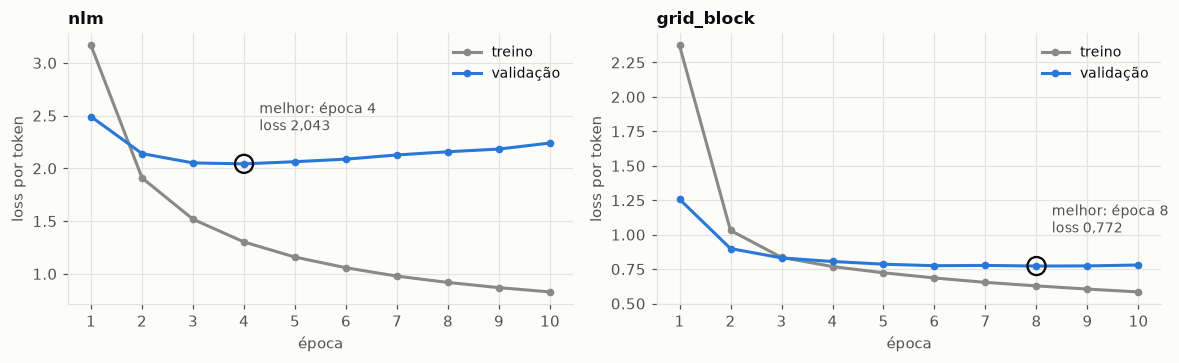

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, modo in zip(axes, hist):
    h = hist[modo]
    epocas = range(1, len(h["train"]) + 1)
    melhor = int(np.argmin(h["val"])) + 1
    ax.plot(epocas, h["train"], color=k.CINZA, lw=2, marker="o", ms=4, label="treino")
    ax.plot(epocas, h["val"], color=k.AZUL, lw=2, marker="o", ms=4, label="validação")
    ax.scatter([melhor], [min(h["val"])], s=140, facecolors="none", edgecolors=k.TINTA, linewidths=1.5, zorder=3)
    ax.annotate(f"melhor: época {melhor}\nloss {k.br(min(h['val']), 3)}", (melhor, min(h["val"])),
                xytext=(10, 22), textcoords="offset points", fontsize=9, color=k.TINTA2)
    ax.set_title(modo, loc="left"); ax.set_xlabel("época"); ax.set_ylabel("loss por token")
    ax.set_xticks(list(epocas)); ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

No nlm, a validação piora depois da época 4 enquanto o treino continua caindo: é **sobreajuste** (o modelo começa a decorar o treino). Por isso o `train.py` salva em `best.pt` os pesos da época com a menor loss de validação, e é esse arquivo que usamos em tudo. No grid_block a melhor época é a 8.

Os dois gráficos têm escalas diferentes de propósito: a loss do nlm e a do grid_block **não são comparáveis** (vocabulários diferentes, tokens que significam coisas diferentes).

## Três formas de ler o mesmo número

- **Loss** (nats por token): o que o treino minimiza.
- **Perplexidade** = e^loss: "entre quantos tokens o modelo fica em dúvida, em média". Perplexidade 2 é como jogar uma moeda a cada token.
- **Bits por segundo:** quantos bits o modelo gasta para descrever um segundo de música. Não depende do vocabulário, então é a medida que **compara nlm com grid_block**. Menos é melhor.

In [3]:
linhas = []
for modo in hist:
    val = k.ler_json(pasta / modo / "val_metrics.json")
    teste = k.ler_json(pasta / modo / "test_metrics.json")
    linhas.append({"modo": modo, "melhor época": val["best_epoch"],
                   "loss (validação)": k.br(min(hist[modo]["val"]), 4),
                   "bits/s (validação)": k.br(val["val_song_level"]["bits_per_second"], 1),
                   "loss (teste)": k.br(teste["test_loss"], 4),
                   "perplexidade (teste)": k.br(teste["test_ppl"], 2)})
k.tabela(linhas)

| modo | melhor época | loss (validação) | bits/s (validação) | loss (teste) | perplexidade (teste) |
|---|---|---|---|---|---|
| nlm | 4 | 2,0429 | 85,6 | 2,0607 | 7,85 |
| grid_block | 8 | 0,7723 | 27,9 | 0,7668 | 2,15 |

O grid_block descreve a mesma música com cerca de um terço dos bits por segundo do nlm. Ou seja: nessa representação, a música fica mais previsível para a LSTM.

## O que o modelo prevê, na prática

Carregamos o `best.pt` do nlm, damos o começo de uma música real e olhamos o que ele acha que vem depois.

começo da música:
BOS               LOOP_START        PATTERN_START     REF_SPEED_16      CH1_INST_2        CH1_VOL_3         CH1_FX_7          CH1_NOTEON_17   
CH2_INST_0        CH2_VOL_5         CH2_NOTEON_5      CH3_INST_0        CH3_VOL_5         CH3_FX_3          CH3_NOTEON_21     WT_16           
CH1_VOL_2         CH1_NOTEON_21     CH2_NOTEOFF       CH3_NOTEOFF       WT_16             CH1_VOL_1         CH1_NOTEON_24     CH2_NOTEON_17   


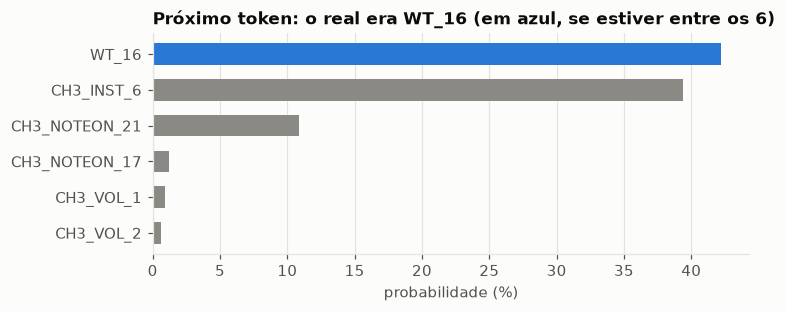

In [4]:
modelo, tok, ckpt = k.carregar_modelo("nlm")
musica = k.musicas_reais(155)[154]
ids = tok.encode_song_to_ids(musica)
prefixo = ids[:24]
print("começo da música:")
k.mostrar_tokens(tok.ids_to_tokens(prefixo), n=24)

with torch.no_grad():
    logits, _ = modelo(torch.tensor([prefixo]))
prob = torch.softmax(logits[0, -1], dim=-1)
top = torch.topk(prob, 6)
nomes = tok.ids_to_tokens(top.indices.tolist())
certo = tok.ids_to_tokens([ids[24]])[0]

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(nomes, top.values.numpy() * 100, height=0.6,
        color=[k.AZUL if n == certo else k.CINZA for n in nomes])
ax.invert_yaxis(); ax.set_xlabel("probabilidade (%)"); ax.grid(axis="y", visible=False)
ax.set_title(f"Próximo token: o real era {certo} (em azul, se estiver entre os 6)", loc="left")
plt.show()

A loss nada mais é do que isto, repetido em todas as posições: a média de −log(probabilidade dada ao token certo). Calculando na música inteira:

In [5]:
with torch.no_grad():
    logits, _ = modelo(torch.tensor([ids[:-1]]))
loss = torch.nn.functional.cross_entropy(logits[0], torch.tensor(ids[1:])).item()
print(f"loss nesta música: {loss:.3f}   perplexidade: {np.exp(loss):.2f}")
print(f"bits por segundo:  {loss * (len(ids) - 1) / np.log(2) / k.duracao(musica):.1f}")

loss nesta música: 1.901   perplexidade: 6.69
bits por segundo:  96.0


## O que levar daqui

- O modelo aprende a prever o próximo token; a loss de validação diz se ele generaliza.
- Usamos sempre os pesos da melhor época de validação (`best.pt`): época 4 no nlm, época 8 no grid_block.
- No teste: perplexidade 7,85 (nlm) e 2,15 (grid_block), mas esses dois números não se comparam entre si. Em bits/s, que se comparam, o grid_block gasta cerca de um terço (27,9 contra 85,6).

**Experimente:** mude o tamanho do prefixo (`ids[:24]`); troque `"nlm"` por `"grid_block"`; calcule a loss de uma música gerada pelo Markov (`k.musicas_geradas("markov", 5)`) e compare com a de uma música real.

Anterior: [3. Tokenização](03_tokenizacao.ipynb) · Próximo: [5. Geração](05_geracao.ipynb).